# Presión fiscal y empresas de alto crecimiento

In [ ]:
# Parámetros de la gráfica
SLUG = "economia"  # carpeta en research/temas/
GRAFICA_ID = "presion-fiscal-empresas-alto-crecimiento"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Presión fiscal y empresas de alto crecimiento"  # `titulo` de la gráfica en config.json
DESDE = 1976  # primer año candidato (METODOLOGIA §2.3)
UNIVERSO = "ocde"  # ocde | ue27: todos sus países con dato en los dos ejes (METODOLOGIA §2.6)
EJE_X = {"titulo": "Presión fiscal", "unidad": "% del PIB"}
EJE_Y = {"titulo": "Empresas de alto crecimiento", "unidad": "% de las empresas con 10 o más asalariados"}
ANIOS = None  # (desde, hasta) si el config fija una ventana; None = último año común de cada país
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 2  # decimales del CSV (el JSON guarda el valor completo)
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

Cada punto es un país de la OCDE con dato en los dos ejes.

- **Eje horizontal:** la **presión fiscal**, todos los impuestos y cotizaciones sociales que recaudan las administraciones públicas en porcentaje del PIB (el mismo indicador que la gráfica `presion-fiscal` de Fiscalidad).
- **Eje vertical:** el porcentaje de **empresas de alto crecimiento**: empresas con al menos 10 asalariados que aumentan su plantilla más de un 10 % al año durante tres años seguidos, sobre el total de empresas con al menos 10 asalariados.

**Para qué sirve.** Pone junto a los impuestos el peso de las empresas que crecen deprisa: es la comparación que invocan quienes sostienen que una presión fiscal alta frena la creación y el crecimiento de las empresas. Quienes defienden una presión fiscal alta sostienen que financia servicios y bienes públicos que no aparecen en este eje (la otra lectura, con la desigualdad, está en `presion-fiscal-redistribucion`). **La relación entre dos indicadores no muestra que uno cause el otro**: no se dibuja línea de tendencia ni se calcula la correlación.

**Limitaciones.**
- La presión fiscal total incluye impuestos que recaen sobre las empresas y otros que no (el IVA que pagan los consumidores o las cotizaciones de las personas trabajadoras): no mide lo que pagan las empresas.
- Las empresas de alto crecimiento miden el crecimiento del empleo, no el de las ventas, y solo se publican para parte de los países de la OCDE y con años distintos; cada punto usa el último año en que el país tiene dato en los dos ejes.

## 2. Descarga

- **OCDE, Revenue Statistics** (`OECD.CTP.TPS,DSD_REV_COMP_OECD@DF_RSOECD`, versión 2.0): ingresos fiscales totales (`TAX_REV`, `S13`, `_T`) en % del PIB de los 38 países de la OCDE, y las medias que publica (`OECD_REP`, `OECD`).
- **OCDE, demografía empresarial** (`OECD.SDD.TPS,DSD_SDBSBD_ISIC4@DF_BD_EMP_HG`, versión 1.0): empresas de alto crecimiento (`HGE10`, `PT_ENT10`, `S_GE10`) de la actividad `BTNXK`.
- **Contrastes para las notas:** España en Eurostat (`bd_hgnace_r`), qué publica la OCDE de Canadá y la tasa de natalidad de empresas de España (`DF_BD_EMP_B_D`).

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.paises import paises_de
from lib.writer import construir_dispersion_data, write_dispersion_data

PAISES = paises_de(UNIVERSO)

from datetime import date

from lib import eurostat, oecd
from lib.paises import nombre_punto
from lib.tipos import FuenteMeta

AREAS = {c: c for c in PAISES}  # todos los países del universo, con su código como clave de serie
HOY = date.today().isoformat()

# Presión fiscal (OCDE, Revenue Statistics): la misma que fiscalidad/presion-fiscal
DATAFLOW_REV = "OECD.CTP.TPS,DSD_REV_COMP_OECD@DF_RSOECD,2.0"
CLAVE_REV = "{AREA}.TAX_REV.S13._T._T.PT_B1GQ.A"
# Empresas de alto crecimiento (demografía empresarial de la OCDE)
DATAFLOW_HG = "OECD.SDD.TPS,DSD_SDBSBD_ISIC4@DF_BD_EMP_HG,1.0"
# Dimensiones: frecuencia . país . medida (empresas) . actividad . tamaño (10 o más asalariados) . edad (todas)
#              . tipo (empresas con asalariados) . fase (crecimiento del empleo de más del 10 % anual) . unidad
ACTIVIDAD = "BTNXK"  # economía empresarial (secciones B a N de la CIIU/NACE) salvo actividades financieras y de seguros
CLAVE_HG = "A.{AREA}." + f"ENT.{ACTIVIDAD}.S_GE10._T.ENT_EMP.HGE10.PT_ENT10"
# Tasa de natalidad de las empresas con asalariados (solo notas)
DATAFLOW_NAT = "OECD.SDD.TPS,DSD_SDBSBD_ISIC4@DF_BD_EMP_B_D,1.0"
CLAVE_NAT = "A.{AREA}." + f"ENT.{ACTIVIDAD}._T.Y_LT1.ENT_EMP.B.PT_ENT_EM"


def descargar_hg():
    return oecd.get(DATAFLOW_HG, CLAVE_HG, areas=AREAS, desde=DESDE)


def otras_definiciones_hg(area):
    """Qué publica la OCDE de empresas de alto crecimiento para un país sin la definición de la gráfica.

    Con reintentos (`pedir`) y sin tragarse errores: si la consulta falla, el notebook falla en vez
    de escribir unas notas distintas.
    """
    import io

    import requests

    from lib._http import pedir

    r = pedir(
        requests.Session(), f"{oecd.BASE}/{DATAFLOW_HG}/A.{area}.ENT.......", None,
        error_cls=oecd.OecdError, etiqueta=f"empresas de alto crecimiento de {area}",
        mensaje=lambda r: r.text[:200], headers=oecd.CABECERA_CSV,
    )
    return pd.read_csv(io.StringIO(r.text), dtype=str)


def descargar_hg_eurostat():
    """Contraste de España con Eurostat (bd_hgnace_r)."""
    return eurostat.get(
        "bd_hgnace_r", {"freq": "A", "indic_sbs": "ENT_HGRWR_PC", "nace_r2": "B-S_X_O_S94"},
        geos={"ES": "ESP"}, desde=DESDE,
    )


def descargar_natalidad():
    return oecd.get(DATAFLOW_NAT, CLAVE_NAT, areas={"ESP": "ESP"}, desde=DESDE)[0]

x, _ = oecd.get(DATAFLOW_REV, CLAVE_REV, areas=AREAS, desde=DESDE)
y, _ = descargar_hg()
# Medias: lo que publica cada fuente para su agregado (el punto de una media solo si la publican las dos)
media_x, _ = oecd.get(DATAFLOW_REV, CLAVE_REV, areas={"OECD_REP": "OECD_REP", "OECD": "OECD"}, desde=DESDE)
try:
    media_y, _ = oecd.get(DATAFLOW_HG, CLAVE_HG, areas={"OECD": "OECD", "EU27_2020": "EU27_2020"}, desde=DESDE)
except oecd.OecdError as e:
    assert "NoRecordsFound" in str(e), f"error distinto de «sin datos»: {e}"
    media_y = pd.DataFrame(columns=["serie", "periodo", "valor"])
hg_eurostat, _ = descargar_hg_eurostat()
natalidad = descargar_natalidad()
otras_can = otras_definiciones_hg("CAN")
print("Países con presión fiscal:", x["serie"].nunique(), "· con empresas de alto crecimiento:", y["serie"].nunique())
print("Medias de la presión fiscal:", sorted(media_x["serie"].unique()), "· de las empresas de alto crecimiento:", sorted(media_y["serie"].unique()))

Países con presión fiscal: 38 · con empresas de alto crecimiento: 28
Medias de la presión fiscal: ['OECD_REP'] · de las empresas de alto crecimiento: []


## 3. Transformación

1. Los dos ejes se usan tal como los publica la OCDE, sin transformar.
2. **Sin puntos de medias:** la OCDE no publica las empresas de alto crecimiento para su media ni para la UE-27 (se comprueba en la descarga), así que no hay un mismo concepto en los dos ejes.
3. El escritor elige para cada país el último año con dato en los dos ejes, el mismo para `x` e `y`.
4. Para las notas: la comparación con Eurostat y la tasa de natalidad de empresas.

In [ ]:
def unir(xs):
    xs = [str(x) for x in xs]
    return xs[0] if len(xs) == 1 else f"{', '.join(xs[:-1])} y {xs[-1]}"


def es(v, d=1):
    return estilos.formato_es(v, d)


def notas_hg(y, hg_eurostat, natalidad, otras_can):
    """Notas comunes del eje de las empresas de alto crecimiento."""
    _, flujo, version = DATAFLOW_HG.split(",")
    notas = [
        f"Empresas de alto crecimiento: OCDE, demografía empresarial ({flujo}, versión {version}): empresas con al "
        "menos 10 asalariados al inicio del periodo cuyo número de asalariados crece de media más de un 10 % al año "
        "durante tres años, en porcentaje de las empresas con al menos 10 asalariados (HGE10, PT_ENT10, S_GE10).",
        f"Actividad: economía empresarial salvo actividades financieras y de seguros ({ACTIVIDAD}, secciones B a N "
        "salvo K), el agregado de actividad con más países de la OCDE en esta definición.",
        "Mide el crecimiento del empleo, no el de la facturación, y no cuenta las empresas sin asalariados ni las "
        "que no crecen, a diferencia de la tasa de natalidad de empresas.",
    ]
    can = otras_can
    if len(can) and "HGE10" not in set(can["BUSINESS_STAGE"]):
        etapas = sorted(set(can["BUSINESS_STAGE"]) & {"HGE20", "HGT20", "HGE10T20"})
        notas.append(
            "Canadá no aparece: la OCDE solo publica sus empresas de alto crecimiento con otra definición "
            f"({unir(etapas)}: crecimiento de más del 20 % anual), sin la del 10 % de esta gráfica."
        )
    esp = y[y["serie"] == "ESP"].set_index("periodo")["valor"]
    eu = hg_eurostat.set_index("periodo")["valor"]
    comunes = sorted(set(esp.index) & set(eu.index))
    if comunes:
        a = comunes[-1]
        notas.append(
            f"España en Eurostat (bd_hgnace_r, industria, construcción y servicios salvo administración pública y "
            f"asociaciones, B-S_X_O_S94): {es(eu[a], 2)} % en {a}, frente al {es(esp[a], 2)} % de la OCDE ({ACTIVIDAD}); "
            "las dos fuentes no cubren las mismas actividades."
        )
    if len(natalidad):
        n = natalidad.sort_values("periodo").iloc[-1]
        notas.append(
            f"Tasa de natalidad de las empresas con asalariados de España (OCDE, {DATAFLOW_NAT.split(',')[1]}, "
            f"{ACTIVIDAD}): {es(n['valor'])} % de las empresas activas en {int(n['periodo'])}. No se usa en la gráfica: "
            "cuenta todas las empresas nuevas, también las pequeñas que no crecen."
        )
    return notas


assert media_y.empty, f"La OCDE publica las empresas de alto crecimiento de {sorted(media_y['serie'].unique())}: revisar si se añade el punto"
_, FLUJO_REV, VERSION_REV = DATAFLOW_REV.split(",")
fuentes = [
    FuenteMeta("eje_x", oecd.ORGANISMO, f"{FLUJO_REV} (Revenue Statistics, versión {VERSION_REV}): TAX_REV, S13, _T (TOTALTAX), PT_B1GQ", oecd.URL_EXPLORER, HOY),
    FuenteMeta("eje_y", oecd.ORGANISMO, f"{DATAFLOW_HG.split(',')[1]}: HGE10, PT_ENT10, S_GE10, {ACTIVIDAD}", oecd.URL_EXPLORER, HOY),
]
NOTAS = [
    f"Presión fiscal: OCDE, Revenue Statistics ({FLUJO_REV}, versión {VERSION_REV}): impuestos y cotizaciones sociales "
    "obligatorias recaudados por el conjunto de las administraciones públicas, en porcentaje del PIB.",
    "La presión fiscal total incluye impuestos que recaen sobre las empresas (como el de Sociedades) y otros que no "
    "(como el IVA o las cotizaciones de las personas trabajadoras): no mide lo que pagan las empresas.",
    "Sin punto de la media OCDE ni de la UE-27: la OCDE no publica las empresas de alto crecimiento para esos agregados.",
]
NOTAS += notas_hg(y, hg_eurostat, natalidad, otras_can)

## 4. Visualización

Un punto por país, sin línea de tendencia ni correlación (METODOLOGIA §2.6).

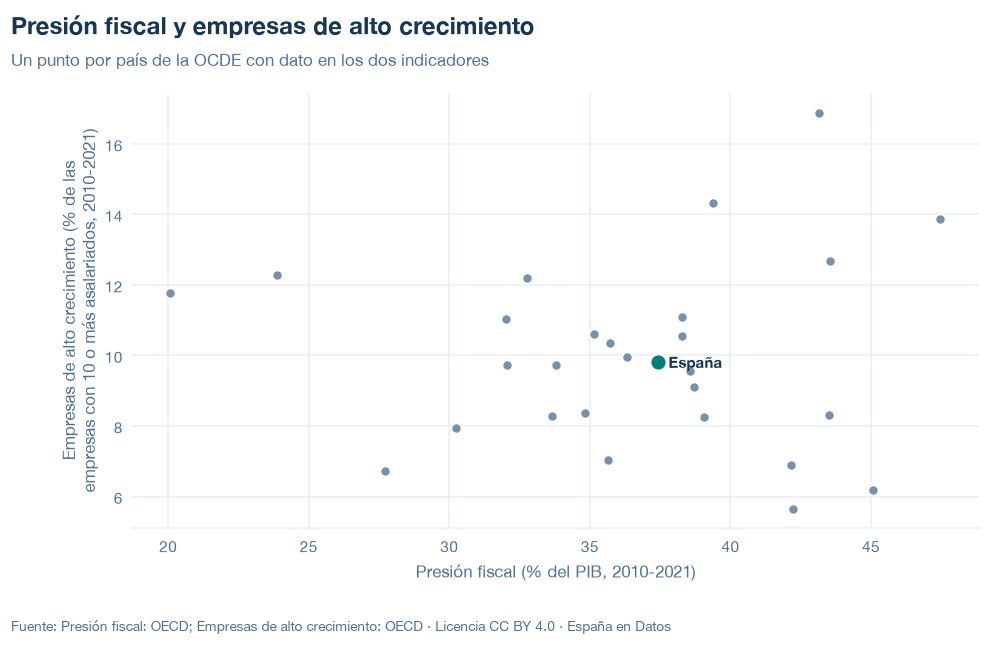

codigo  anio         x         y
   AUT  2021 43.515278  8.319125
   BEL  2021 42.231397  5.656941
   CHE  2017 27.716094  6.722480
   CZE  2021 33.654218  8.284117
   DEU  2021 39.053184  8.247173
   DNK  2021 47.470033 13.881402
   ESP  2021 37.412685  9.813936
   EST  2021 33.799808  9.720605
   FIN  2021 43.540866 12.693133
   FRA  2021 45.059326  6.194945
   GBR  2018 32.761008 12.210964
   GRC  2021 39.373785 14.338316
   HUN  2020 35.701674 10.340394
   IRL  2021 20.080586 11.776052
   ISL  2020 35.648210  7.023604
   ITA  2021 42.141739  6.895741
   LTU  2021 32.002897 11.026698
   LUX  2021 38.269224 10.541248
   LVA  2021 32.045652  9.718193
   NLD  2021 38.264035 11.084942
   NOR  2020 38.714140  9.100798
   NZL  2010 30.230403  7.940371
   POL  2021 36.306536  9.948272
   PRT  2021 35.147059 10.599048
   SVK  2021 34.821612  8.364553
   SVN  2021 38.545185  9.570008
   SWE  2021 43.132529 16.889853
   TUR  2020 23.860801 12.285948


In [ ]:
datos = construir_dispersion_data(
    x, y, fuentes, id=GRAFICA_ID, universo=UNIVERSO, eje_x=EJE_X, eje_y=EJE_Y, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, anios=ANIOS,
)
fig = estilos.figura(datos, titulo=TITULO)
estilos.mostrar(fig)
print(pd.DataFrame(datos["puntos"]).to_string(index=False))

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web (`codigo;pais;anio;eje_x;eje_y`).

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_dispersion_data(
    x, y, fuentes, id=GRAFICA_ID, universo=UNIVERSO, eje_x=EJE_X, eje_y=EJE_Y, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, anios=ANIOS,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/presion-fiscal-empresas-alto-crecimiento.json y data/presion-fiscal-empresas-alto-crecimiento.csv


## 6. Fuentes, notas y licencia

- OCDE, Revenue Statistics: `OECD.CTP.TPS,DSD_REV_COMP_OECD@DF_RSOECD,2.0` (`TAX_REV`, `S13`, `_T`, `PT_B1GQ`).
- OCDE, demografía empresarial: `OECD.SDD.TPS,DSD_SDBSBD_ISIC4@DF_BD_EMP_HG,1.0` y `DF_BD_EMP_B_D` (natalidad, solo notas).
- Eurostat, `bd_hgnace_r` (contraste de España).

La fecha de consulta de cada eje está en `fuentes` del JSON; las notas incluyen los países sin dato y la advertencia de que la relación no muestra causa.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.